This notebook follows the place-name spike workflow in [`spikes_edward_scotland.ipynb`](./spikes_edward_scotland.ipynb).
[`places_1577.ipynb`](./places_1577.ipynb) found that Henry III's reign has the most place mentions of any reign, so instead of following one place it lays out the most-mentioned places side by side across the reign.

In [1]:
import re
import sys
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lxml import etree

sys.path.append("../name_extraction")
from helpers import count_names, load_places

TEI = "{http://www.tei-c.org/ns/1.0}"

### 1. Load Henry III's reign from `08_HenryThird.xml`, dropping the margin notes from the text but keeping the word position of each year given in them (1216–1272), once each and in order.

In [2]:
root = etree.parse("../1577_files/regnal_files/08_HenryThird.xml").getroot()

henry_entry = root.find(f".//{TEI}div[@type='reign'][@n='Henry III']")
if henry_entry is None:
    raise ValueError("Could not find Henry III's reign section.")

# Years of Henry III's reign, and the regnal year ("5.", "22.") that many notes start with.
# Regnal year n is printed beside the year 1216 + n ("3. 1219")
year_pattern = re.compile(r"(?<!\d)12(?:1[6-9]|[2-6]\d|7[0-2])(?!\d)")
regnal_pattern = re.compile(r"\s*(\d{1,2})\b(?!\s*\d)")
first_year = 1216

# Empty every margin note, leaving only a marker such as "@@1242@@" for each year it gives.
for note in list(henry_entry.iter(f"{TEI}note")):
    note_text = " ".join(note.itertext())
    years = [int(year) for year in year_pattern.findall(note_text)]
    regnal = regnal_pattern.match(note_text)
    if regnal and 1 <= int(regnal.group(1)) <= 56:
        years.append(first_year + int(regnal.group(1)))
    tail = note.tail  # the text after a note belongs to the chronicle, so keep it
    note.clear()
    note.tail = tail
    note.text = "".join(f" @@{year}@@ " for year in years)

# List of words (the unit the counts below are binned by), long s written as s, with the markers pulled out
# as (year, word position) pairs
henry_words, year_markers = [], []
for token in " ".join(henry_entry.itertext()).replace("ſ", "s").split():
    marker = re.fullmatch(r"@@(\d{4})@@", token)
    if marker:
        year = int(marker.group(1))
        # Keep each year once and in order: this drops repeats (a note's regnal and printed year, a second
        # "1262") and years quoted out of order ("Anno. 1242. as Mat. West hath", printed after 1244)
        if not year_markers or year > year_markers[-1][0]:
            year_markers.append((year, len(henry_words)))
    else:
        henry_words.append(token)

missing_years = sorted(set(range(1216, 1273)) - {year for year, _ in year_markers})
print(f"{len(henry_words):,} words and {len(year_markers)} marginal years.")
print(f"Years not readable in the margin (cut short in the transcription): {missing_years}\n")
print(textwrap.fill(" ".join(henry_words[:150]), width=150))

95,835 words and 45 marginal years.
Years not readable in the margin (cut short in the transcription): [1231, 1235, 1241, 1243, 1245, 1246, 1247, 1248, 1256, 1263, 1265, 1266]

Henry the thirde. HEnry, the thirde of that name, the eldest sonne of King Iohn, a childe, of the age of nine yeres, began his raigne ouer the Realme
of Englande the nineteenth daye of October, in the yeare of our Lord in the seuenth yeare of the Emperour Fredericke the second, and in the yeare of
the raigne of Phillip the second King of Fraunce. Immediately after the deathe of his father Kyng Iohn, William Marshall Earle of Pembroke generall of
his fathers army, broughte this yong Prince with hys brother and sisters vnto Glowcester, and there called a Counsell of all such Lords, as had taken
part with Kyng Iohn: and soone after, when it was once openly knowen, that the sonnes and daughters of the late deceassed Prince were brought into a
place of safetie, a great number of the Lords and chiefe Barons of the Rea

### 2. Count every place's mentions in consecutive 500-word sections with the shared `count_names` function, split them into place mentions and titles ("Earle of Chester", "Bishop of Winchester", which name people), rank the places by place mentions, and pick the ones to lay out.

In [3]:
window_size = 500
top_n = 6
# Leicester has the reign's second-most mentions in all, but nearly all of them are "Earle of Leicester"
extra_places = ["Leicester"]

# One text per section, keyed by the word position where the section starts
sections = {
    start: " ".join(henry_words[start : start + window_size])
    for start in range(0, len(henry_words), window_size)
}

# count_names normalizes spelling in both the text and the place names, and sums spellings of the same place.
# With strip_titles=True it skips titles such as "Earle of Leicester", so the difference from counting
# everything is the title mentions. Rows are places, columns are sections
places = load_places("../name_extraction/entity_names/holinshed_places.csv")
all_counts = count_names(places, sections)
place_counts = count_names(places, sections, strip_titles=True)
title_counts = all_counts - place_counts

# Rank the places by place mentions, then keep the top few plus the extras
mention_totals = pd.DataFrame(
    {"place": place_counts.sum(axis=1), "title": title_counts.sum(axis=1)}
).sort_values("place", ascending=False)
top_places = mention_totals.loc[mention_totals.head(top_n).index.tolist() + extra_places]

print(
    f"{mention_totals['place'].sum()} place mentions (plus {mention_totals['title'].sum()} in titles) "
    f"across {len(sections)} sections; the {len(top_places)} places laid out below account for "
    f"{top_places['place'].sum()} of them."
)
display(mention_totals.head(12))

717 place mentions (plus 223 in titles) across 192 sections; the 7 places laid out below account for 402 of them.


,place,title
London,166,8
Rome,60,0
Westminster,56,5
Oxford,43,3
Winchester,37,33
Chester,25,40
Paris,22,0
Scotland,22,0
Hereford,19,14
York,18,5


### 3. Plot the chosen places across the reign as one row per place, on a shared year axis, with title mentions stacked in a lighter shade on top of place mentions.

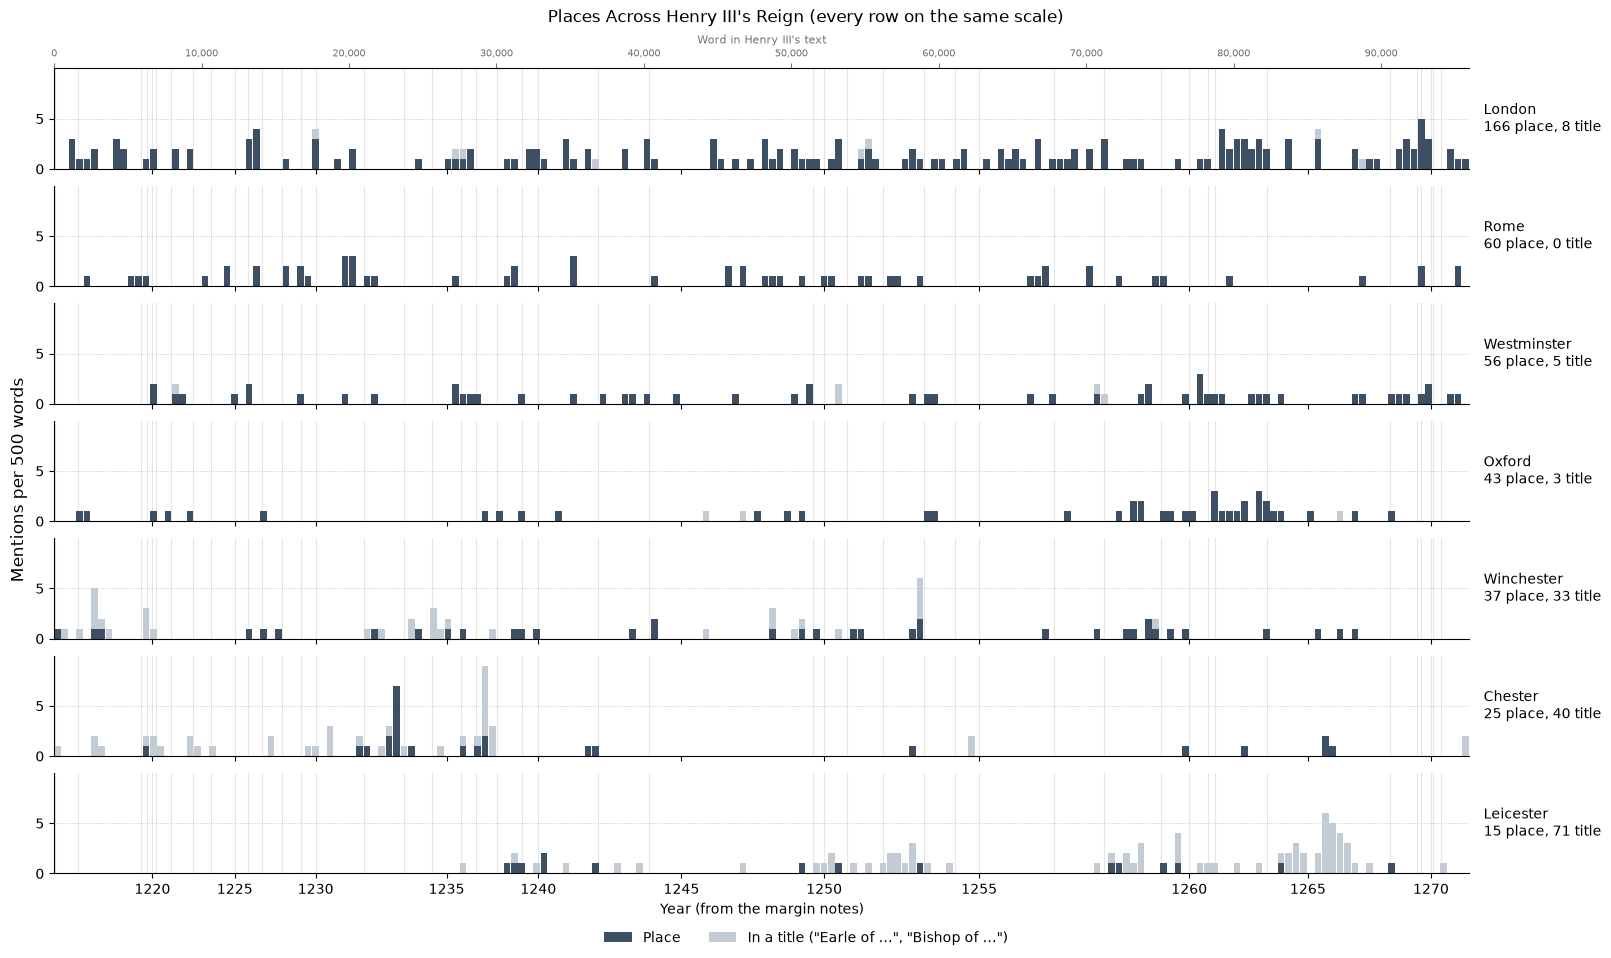

In [ ]:
# One neutral colour for place mentions and a lighter one for titles: the row labels name each place
place_color, title_color = "#3d4f63", "#c3cbd5"

# Year axis: each year sits at the word where its margin note appears, and years missing from the
# margin are placed between their neighbours
marker_years, marker_positions = zip(*year_markers)
label_years = list(range(1220, 1271, 5))
label_positions = np.interp(label_years, marker_years, marker_positions)

n_lanes = len(top_places)
fig, lanes = plt.subplots(
    n_lanes, 1, figsize=(16, 1.1 * n_lanes + 1.8), sharex=True, layout="constrained"
)

# Every row uses the same scale, so bar heights compare across places
max_count = all_counts.loc[top_places.index].to_numpy().max()

for ax, place in zip(lanes, top_places.index):
    # Pale year lines and a faint line at 5 mentions, both behind the bars
    for _, word_position in year_markers:
        ax.axvline(word_position, color="0.9", linewidth=0.8, zorder=0)
    ax.axhline(5, color="0.75", linewidth=0.6, linestyle=":", zorder=1)

    bar_style = dict(width=window_size * 0.9, align="edge", zorder=2)
    ax.bar(place_counts.columns, place_counts.loc[place], color=place_color, label="Place", **bar_style)
    ax.bar(
        title_counts.columns,
        title_counts.loc[place],
        bottom=place_counts.loc[place],
        color=title_color,
        label='In a title ("Earle of …", "Bishop of …")',
        **bar_style,
    )
    ax.set_ylim(0, max_count + 1)
    ax.set_yticks(range(0, max_count + 1, 5))
    ax.spines[["top", "right"]].set_visible(False)

    # Name each row on its right-hand side
    ax.text(
        1.01,
        0.5,
        f"{place}\n{top_places.loc[place, 'place']} place, {top_places.loc[place, 'title']} title",
        transform=ax.transAxes,
        ha="left",
        va="center",
    )

# Years along the bottom, every fifth year
lanes[-1].set_xlim(0, len(sections) * window_size)
lanes[-1].set_xticks(label_positions, labels=label_years)
lanes[-1].set_xlabel("Year (from the margin notes)")

# Word position as a small secondary axis along the top
word_axis = lanes[0].secondary_xaxis("top")
word_axis.set_xticks(range(0, len(henry_words) + 1, 10000))
word_axis.xaxis.set_major_formatter("{x:,.0f}")
word_axis.tick_params(labelsize=7, colors="0.45")
word_axis.set_xlabel("Word in Henry III's text", fontsize=8, color="0.45")

fig.suptitle("Places Across Henry III's Reign")
fig.supylabel(f"Mentions per {window_size} words")
handles, labels = lanes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2, frameon=False)
plt.show()

# TODO: Try starting at 16,000, removing year markers

### 4. List each chosen place's busiest section (place mentions only), with the last year printed in the margin before it.

In [5]:
def year_before(word_position):
    """Last year printed in the margin at or before a word position."""
    earlier = [year for year, position in year_markers if position <= word_position]
    return earlier[-1] if earlier else None


# Place mentions of the chosen places, titles left out
top_place_counts = place_counts.loc[top_places.index]

busiest = pd.DataFrame(
    {
        "place_mentions": top_places["place"],
        "title_mentions": top_places["title"],
        "busiest_section_start": top_place_counts.idxmax(axis=1),
        "mentions_there": top_place_counts.max(axis=1),
    }
)
busiest["year_in_margin"] = busiest["busiest_section_start"].map(year_before)

display(busiest)

,place_mentions,title_mentions,busiest_section_start,mentions_there,year_in_margin
London,166,8,92500,5,1268
Rome,60,0,19500,3,1230
Westminster,56,5,77500,3,1260
Oxford,43,3,78500,3,1261
Winchester,37,33,40500,2,1244
Chester,25,40,23000,7,1232
Leicester,15,71,33000,2,1240


### 5. Read the single busiest section among them: the place and section with the most place mentions.

In [6]:
spike_place, spike_start = top_place_counts.stack().idxmax()
print(
    f"{spike_place}: {top_place_counts.loc[spike_place, spike_start]} place mentions in words "
    f"{spike_start:,}-{spike_start + window_size:,} (margin year {year_before(spike_start)})\n"
)
print(textwrap.fill(sections[spike_start], width=150))

Chester: 7 place mentions in words 23,000-23,500 (margin year 1232)

to be remembred, that the afore mentioned Erle Ranulf (or Randulf whether ye list to call him) atchieued many high enterprises in his time, as partly
in this booke ye haue alredie heard: he held sore warres agaynst the Welchmen, till at length an agreement was concluded betwixt him & Llewellin
prince of Wales. I remember I haue read in an olde record, that vpon a time as this Earle passed into Wales with an army, his chance was to be ouerset
by the Welch men, so that he was driuen to retire into a castell, wherin the Welchmen did besiege him. And as it fortuned at that time, Roger Lacy y
Conestable of Chester was not thē with him, but left behind at Chester to see the Citie kept in order (for as it should seem, their solemne playes
which cōmonly are vsed at Whitsuntide were then in hande, or else their Faire which is kept at Midsommer.) The Erle therfore sent a messenger in all
possible hast vnto his Conestable, pra